In [1]:
!pip install scikit-fuzzy

  Created wheel for scikit-fuzzy: filename=scikit_fuzzy-0.4.2-py3-none-any.whl size=894073 sha256=65154306663cc47b61ef97e4cdddd2696ff9001cb29946936dd208c7989399d8
  Stored in directory: /root/.cache/pip/wheels/4f/86/1b/dfd97134a2c8313e519bcebd95d3fedc7be7944db022094bc8
Successfully built scikit-fuzzy


Enter a 6-digit password: %%aB24
Password Strength: Strong


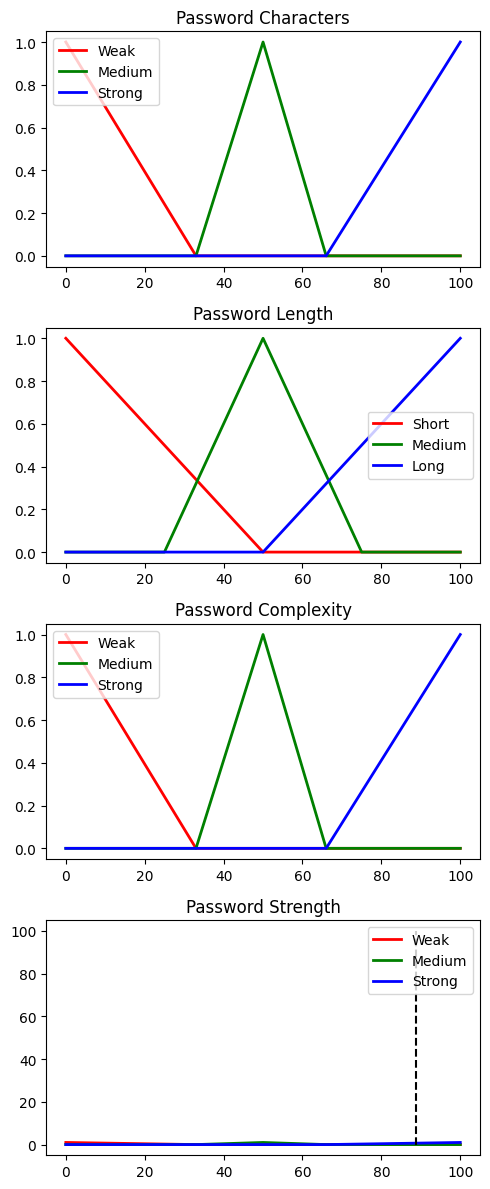

In [2]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import matplotlib.pyplot as plt

# Define fuzzy variables
password_characters = ctrl.Antecedent(np.arange(0, 101, 1), 'password_characters')
password_length = ctrl.Antecedent(np.arange(0, 101, 1), 'password_length')
password_complexity = ctrl.Antecedent(np.arange(0, 101, 1), 'password_complexity')
password_strength = ctrl.Consequent(np.arange(0, 101, 1), 'password_strength')

# Define fuzzy membership functions for password characters
password_characters['weak'] = fuzz.trimf(password_characters.universe, [0, 0, 33])
password_characters['medium'] = fuzz.trimf(password_characters.universe, [33, 50, 66])
password_characters['strong'] = fuzz.trimf(password_characters.universe, [66, 100, 100])

# Define fuzzy membership functions for password length
password_length['short'] = fuzz.trimf(password_length.universe, [0, 0, 50])
password_length['medium'] = fuzz.trimf(password_length.universe, [25, 50, 75])
password_length['long'] = fuzz.trimf(password_length.universe, [50, 100, 100])

# Define fuzzy membership functions for password complexity
password_complexity['weak'] = fuzz.trimf(password_complexity.universe, [0, 0, 33])
password_complexity['medium'] = fuzz.trimf(password_complexity.universe, [33, 50, 66])
password_complexity['strong'] = fuzz.trimf(password_complexity.universe, [66, 100, 100])

# Define fuzzy membership functions for password strength
password_strength['weak'] = fuzz.trimf(password_strength.universe, [0, 0, 33])
password_strength['medium'] = fuzz.trimf(password_strength.universe, [33, 50, 66])
password_strength['strong'] = fuzz.trimf(password_strength.universe, [66, 100, 100])

# Define fuzzy rules
rule1 = ctrl.Rule(password_characters['weak'], password_strength['weak'])
rule2 = ctrl.Rule(password_characters['medium'], password_strength['medium'])
rule3 = ctrl.Rule(password_characters['strong'], password_strength['strong'])
rule4 = ctrl.Rule(password_characters['weak'] & password_length['short'] & password_complexity['weak'],
                  password_strength['weak'])
rule5 = ctrl.Rule(password_characters['medium'] & password_length['medium'] & password_complexity['medium'],
                  password_strength['medium'])
rule6 = ctrl.Rule(password_characters['strong'] & password_length['long'] & password_complexity['strong'],
                  password_strength['strong'])
rule7 = ctrl.Rule(password_characters['weak'] & password_length['long'] & password_complexity['strong'],
                  password_strength['medium'])
rule8 = ctrl.Rule(password_characters['medium'] & password_length['short'] & password_complexity['strong'],
                  password_strength['medium'])
rule9 = ctrl.Rule(password_characters['strong'] & password_length['medium'] & password_complexity['weak'],
                  password_strength['medium'])

# Create the control system
controller = ctrl.ControlSystem([rule1, rule2, rule3, rule4, rule5, rule6, rule7, rule8, rule9])
simulation = ctrl.ControlSystemSimulation(controller)

# Prompt the user to enter password information
password = input("Enter a 6-digit password: ")
has_number = any(char.isdigit() for char in password)
has_lowercase = any(char.islower() for char in password)
has_uppercase = any(char.isupper() for char in password)
has_special = any(not char.isalnum() for char in password)

# Set the input values for the simulation
if has_number and has_lowercase and has_uppercase and has_special:
    simulation.input['password_characters'] = 100
elif has_number and (has_lowercase or has_uppercase) and has_special:
    simulation.input['password_characters'] = 75
elif (has_lowercase or has_uppercase) and has_number:
    simulation.input['password_characters'] = 50
else:
    simulation.input['password_characters'] = 0

# Set the input values for password length and complexity
if len(password) <= 4:
    password_length_input = 0
elif len(password) <= 8:
    password_length_input = 50
else:
    password_length_input = 100

if (has_number and has_lowercase and has_uppercase and has_special):
    password_complexity_input = 100
elif (has_number and (has_lowercase or has_uppercase) and has_special):
    password_complexity_input = 75
elif ((has_lowercase or has_uppercase) and has_number):
    password_complexity_input = 50
else:
    password_complexity_input = 0

# Set the input values for the simulation
simulation.input['password_length'] = password_length_input
simulation.input['password_complexity'] = password_complexity_input

# Compute the password strength
simulation.compute()

# Get the password strength output
password_strength_output = simulation.output['password_strength']

# Determine the password strength category based on the output value
if password_strength_output <= 33:
    strength_category = "Weak"
elif password_strength_output <= 66:
    strength_category = "Medium"
else:
    strength_category = "Strong"

# Print the password strength category
print("Password Strength:", strength_category)

# Plot the membership functions
fig, (ax0, ax1, ax2, ax3) = plt.subplots(nrows=4, figsize=(5, 12))

ax0.plot(password_characters.universe, fuzz.trimf(password_characters.universe, [0, 0, 33]), 'r', linewidth=2,
         label='Weak')
ax0.plot(password_characters.universe, fuzz.trimf(password_characters.universe, [33, 50, 66]), 'g', linewidth=2,
         label='Medium')
ax0.plot(password_characters.universe, fuzz.trimf(password_characters.universe, [66, 100, 100]), 'b', linewidth=2,
         label='Strong')
ax0.set_title('Password Characters')
ax0.legend()

ax1.plot(password_length.universe, fuzz.trimf(password_length.universe, [0, 0, 50]), 'r', linewidth=2,
         label='Short')
ax1.plot(password_length.universe, fuzz.trimf(password_length.universe, [25, 50, 75]), 'g', linewidth=2,
         label='Medium')
ax1.plot(password_length.universe, fuzz.trimf(password_length.universe, [50, 100, 100]), 'b', linewidth=2,
         label='Long')
ax1.set_title('Password Length')
ax1.legend()

ax2.plot(password_complexity.universe, fuzz.trimf(password_complexity.universe, [0, 0, 33]), 'r', linewidth=2,
         label='Weak')
ax2.plot(password_complexity.universe, fuzz.trimf(password_complexity.universe, [33, 50, 66]), 'g', linewidth=2,
         label='Medium')
ax2.plot(password_complexity.universe, fuzz.trimf(password_complexity.universe, [66, 100, 100]), 'b', linewidth=2,
         label='Strong')
ax2.set_title('Password Complexity')
ax2.legend()

ax3.plot(password_strength.universe, fuzz.trimf(password_strength.universe, [0, 0, 33]), 'r', linewidth=2,
         label='Weak')
ax3.plot(password_strength.universe, fuzz.trimf(password_strength.universe, [33, 50, 66]), 'g', linewidth=2,
         label='Medium')
ax3.plot(password_strength.universe, fuzz.trimf(password_strength.universe, [66, 100, 100]), 'b', linewidth=2,
         label='Strong')
ax3.fill_between(password_strength.universe, fuzz.trimf(password_strength.universe, [0, 0, 33]),
                 fuzz.trimf(password_strength.universe, [66, 100, 100]), facecolor='orange', alpha=0.5)
ax3.vlines(password_strength_output, ymin=0, ymax=100, colors='k', linestyles='dashed')
ax3.set_title('Password Strength')
ax3.legend()

plt.tight_layout()
plt.show()
